# Travel Reimbursement Approval Agent
### AI Developer Candidate Assignment

### Overview
This notebook implements an automated, auditable Travel Reimbursement Approval Agent following the **"AI extracts, Python decides"** architecture.

In [ ]:

import os

os.environ["NVIDIA_API_KEY"] = "YOUR_NVIDIA_API_KEY" # set you api key

model_name= "nvidia/nemotron-3-ultra-550b-a55b"  #set you nvidia model

In [ ]:
%pip install langchain langchain-nvidia-ai-endpoints pydantic matplotlib

In [127]:

import os
import json
import re
from datetime import datetime
from typing import List, Literal, Dict, Any
import matplotlib
matplotlib.use("Agg")  # Headless backend for image saving
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field

In [128]:

# ==============================================================================
# 1. POLICY RULES (Appendix A Constants)
# ==============================================================================

POLICY = {
    "POL-CAT-01": "Eligible categories: airfare (economy), lodging, meals, ground transport, conference fees",
    "POL-CAT-02": "Ineligible categories: spa, minibar, alcohol, gym, personal entertainment, gifts (deducted in full)",
    "POL-PD-01": "Meals per-diem: max $75/day (excess deducted)",
    "POL-PD-02": "Lodging per-diem: max $200/night (excess deducted)",
    "POL-PD-03": "Ground transport per-diem: max $50/day (excess deducted)",
    "POL-AIR-01": "Airfare class: economy reimbursable; business/first-class routes to Manual Review",
    "POL-RCT-01": "Receipt required for line items > $25, and all airfare/lodging regardless of amount",
    "POL-RCT-02": "Missing required receipt routes claim to Manual Review (no silent rejections)",
    "POL-APR-01": "Auto-approve tier: reimbursable total <= $500",
    "POL-APR-02": "Manager tier: reimbursable total > $500 and <= $2,000",
    "POL-APR-03": "Director tier: total > $2,000 requires Manual Review",
    "POL-TIME-01": "Timeliness: claims must be submitted within 30 days of trip end"
}


In [129]:

# ==============================================================================
# 2. APPENDIX B SAMPLE CLAIMS
# ==============================================================================

CLAIMS = [
    {
        "claim_id": "CLM-001",
        "employee": "A. Rivera",
        "trip_start": "2026-06-10",
        "trip_end": "2026-06-12",
        "submitted": "2026-06-20",
        "purpose": "Attend 2-day industry conference (business)",
        "items": [
            {"category": "airfare", "description": "Round-trip economy airfare", "amount": 420.00, "receipt": True},
            {"category": "lodging", "description": "Hotel, 2 nights @ $180", "amount": 360.00, "receipt": True},
            {"category": "meals", "description": "Meals, 3 days @ ~$60/day", "amount": 180.00, "receipt": True},
            {"category": "conference_fees", "description": "Conference registration", "amount": 150.00, "receipt": True}
        ]
    },
    {
        "claim_id": "CLM-002",
        "employee": "B. Osei",
        "trip_start": "2026-06-14",
        "trip_end": "2026-06-15",
        "submitted": "2026-06-25",
        "purpose": "Weekend hotel stay",
        "items": [
            {"category": "spa", "description": "Hotel spa package", "amount": 300.00, "receipt": True},
            {"category": "minibar", "description": "In-room minibar", "amount": 80.00, "receipt": True}
        ]
    },
    {
        "claim_id": "CLM-003",
        "employee": "C. Nakamura",
        "trip_start": "2026-06-08",
        "trip_end": "2026-06-10",
        "submitted": "2026-06-22",
        "purpose": "Client site visit (business)",
        "items": [
            {"category": "airfare", "description": "Round-trip economy airfare", "amount": 300.00, "receipt": True},
            {"category": "lodging", "description": "Hotel, 2 nights @ $250", "amount": 500.00, "receipt": True},
            {"category": "meals", "description": "Meals, 2 days @ $70/day", "amount": 140.00, "receipt": True}
        ]
    },
    {
        "claim_id": "CLM-004",
        "employee": "D. Fischer",
        "trip_start": "2026-06-16",
        "trip_end": "2026-06-18",
        "submitted": "2026-06-28",
        "purpose": "International vendor negotiation (business)",
        "items": [
            {"category": "airfare", "description": "Business-class international airfare", "amount": 2400.00, "receipt": True},
            {"category": "lodging", "description": "Hotel, 3 nights", "amount": 600.00, "receipt": False}
        ]
    },
    {
        "claim_id": "CLM-005",
        "employee": "E. Haddad",
        "trip_start": "2026-06-11",
        "trip_end": "2026-06-11",
        "submitted": "2026-06-24",
        "purpose": "Client dinner / business development",
        "items": [
            {"category": "meals", "description": "Client dinner for 4 (business development)", "amount": 220.00, "receipt": False}
        ]
    }
]


In [ ]:

# ==============================================================================
# 3. EXTRACTION SCHEMA & FUNCTION (AI Extracts + Keyword Fallback)
# ==============================================================================
api_key = os.environ.get("NVIDIA_API_KEY")
if api_key:
    print(" API Key is SET")
else:
    print(" API Key is NOT SET")


    
class ItemInfo(BaseModel):
    category: Literal["airfare", "lodging", "meals", "ground_transport", "conference", "ineligible", "other"]
    is_ineligible: bool        # alcohol, minibar, spa, gym, entertainment, movies, shopping, gifts, fines, personal
    is_premium_cabin: bool     # business/first class (airfare only)
    nights: int                # lodging, else 0
    days: int                  # meals/ground transport, else 0
    ambiguous: bool            # description unclear or business purpose doubtful

class ClaimExtraction(BaseModel):
    items: List[ItemInfo]      # same order as input
    explanation: str           # 2-3 sentence policy-grounded justification (writing only; it does not decide)


def extract_claim_info(claim: dict) -> tuple[List[ItemInfo], bool]:

    from langchain_nvidia_ai_endpoints import ChatNVIDIA
    import time

    MAX_RETRIES = 3

    try:
        llm = ChatNVIDIA(
            model=model_name,
            api_key=api_key,
            temperature=0,
            max_completion_tokens=4096
        )

        structured_llm = llm.with_structured_output(ClaimExtraction)

        prompt = (
            f"Extract structured item details for claim {claim['claim_id']} ({claim['purpose']}).\n"
            f"Rules:\n"
            f"- is_ineligible: True for non-reimbursable personal expenses (spa, minibar, alcohol, gym, entertainment, movies, gifts, fines, personal items). Category should be 'ineligible'.\n"
            f"- is_premium_cabin: True for business/first-class airfare\n"
            f"- nights: count of hotel nights (0 if not specified in description)\n"
            f"- days: count of days for meals/transport (0 if not specified in description)\n"
            f"- ambiguous: True ONLY if the description is too vague, cryptic, or unknown to determine what the expense is (e.g., 'misc expense', 'services'). Note: Known ineligible items (spa, minibar, alcohol) are NOT ambiguous; mark them with is_ineligible=True and ambiguous=False.\n"
            f"- Return exactly one output item for each input line item.\n"
            f"Line items:\n"
            + "\n".join(f"- {it['category']}: {it['description']} (${it['amount']})" for it in claim["items"])
        )

        for attempt in range(1, MAX_RETRIES + 1):

            try:
                print(f"[{claim['claim_id']}] Attempt {attempt}/{MAX_RETRIES}")

                res = structured_llm.invoke(prompt)

                res = ClaimExtraction.model_validate(res.model_dump())

                if len(res.items) != len(claim["items"]):
                    raise ValueError("Incorrect number of extracted items.")

                return res.items, False

            except Exception as e:
                print(f"[{claim['claim_id']}] Attempt {attempt} failed: {e}")

                if attempt < MAX_RETRIES:
                    time.sleep(2)

    except Exception as e:
        print(f"[{claim['claim_id']}] Model initialization failed: {e}")

    # Fallback after all failures
    print(f"[{claim['claim_id']}] Using manual review fallback.")

    fallback_items = [
        ItemInfo(
            category="other",
            is_ineligible=False,
            is_premium_cabin=False,
            nights=0,
            days=0,
            ambiguous=True
        )
        for _ in claim["items"]
    ]

    return fallback_items, True

    

In [131]:

# ==============================================================================
# 4. PYTHON RULE ENGINE (Plain Conditionals, ~60 lines)
# ==============================================================================

def evaluate_claim_rules(claim: dict, items: List[ItemInfo], used_fallback: bool) -> dict:
    tools_used = ["timeliness_check"]
    policy_refs = set(["POL-TIME-01"])
    missing_docs = []
    manual_review = False
    reasons = []

    if used_fb:
        return {
            "claim_id": claim["claim_id"],
            "decision": "MANUAL_REVIEW",
            "approved_amount": 0.0,
            "deducted_amount": 0.0,
            "missing_docs": [],
            "policy_refs": [],
            "confidence": 0.0,
            "explanation": "AI extraction failed after 3 attempts. Manual review is required.",
            "tools_used": [tools_used]
        }


    # 1. Submission window: > 30 days routes to Manual Review
    days = (datetime.strptime(claim["submitted"], "%Y-%m-%d") - datetime.strptime(claim["trip_end"], "%Y-%m-%d")).days
    if days > 30:
        manual_review = True
        reasons.append(f"Late submission ({days} days > 30)")

    approved_total, deducted_total = 0.0, 0.0
    ELIGIBLE_CATEGORIES = {"airfare", "lodging", "meals", "ground_transport", "conference_fees", "conference"}

    # 2. Per-item evaluation using extracted fields
    for raw, ext in zip(claim["items"], items):
        amt, raw_cat, desc = float(raw["amount"]), raw["category"].lower(), raw["description"]
        receipt = bool(raw.get("receipt", False))
        desc_lower = desc.lower()

        # Reconcile semantic flags
        is_ineligible = (
            ext.is_ineligible
            or ext.category == "ineligible"
            or raw_cat in ["spa", "minibar", "alcohol", "personal_shopping"]
            or any(k in desc_lower for k in ["spa", "minibar", "alcohol", "gym", "entertainment", "movie", "gift", "personal"])
        )
        is_premium = (
            ext.is_premium_cabin
            or ("business" in desc_lower)
            or ("first" in desc_lower)
        )
        cat = "ineligible" if is_ineligible else (ext.category if ext.category != "other" else raw_cat)

        # Extract nights/days from LLM or description regex
        nights = ext.nights
        if nights <= 0:
            n_match = re.search(r'(\d+)\s*nights?', desc_lower)
            if n_match:
                nights = int(n_match.group(1))

        days_cnt = ext.days
        if days_cnt <= 0:
            d_match = re.search(r'(\d+)\s*days?', desc_lower)
            if d_match:
                days_cnt = int(d_match.group(1))

        # Check for ambiguous expense flag
        if ext.ambiguous:
            manual_review = True
            reasons.append(f"Ambiguous expense: {desc}")

        # Conflicting expense description and amount
        rate_match = re.search(r'(\d+)\s*(?:nights?|days?)\s*@\s*~?\$?([0-9]+(?:\.[0-9]+)?)', desc, re.IGNORECASE)
        if rate_match:
            qty = float(rate_match.group(1))
            rate = float(rate_match.group(2))
            expected_calc = qty * rate
            if abs(expected_calc - amt) > 1.0:
                manual_review = True
                reasons.append(f"Conflicting expense description and amount: '{desc}' implies ${expected_calc:.2f} but claimed ${amt:.2f}")

        # Unknown or unlisted expense category (POL-CAT-01)
        if not is_ineligible and raw_cat not in ELIGIBLE_CATEGORIES and cat not in ELIGIBLE_CATEGORIES:
            manual_review = True
            reasons.append(f"Unknown or unlisted expense category: '{raw_cat}' ({desc})")

        #  Missing duration for per-diem capped expenses
        if (cat == "lodging" or raw_cat == "lodging") and nights <= 0:
            manual_review = True
            reasons.append(f"Missing lodging duration: '{desc}'")
        if (cat in ["meals", "ground_transport"] or raw_cat in ["meals", "ground_transport"]) and days_cnt <= 0:
            trip_duration = (datetime.strptime(claim["trip_end"], "%Y-%m-%d") - datetime.strptime(claim["trip_start"], "%Y-%m-%d")).days
            if trip_duration > 0 or ext.ambiguous:
                manual_review = True
                reasons.append(f"Missing duration for {raw_cat}: '{desc}'")

        # Receipt rule: amount > $25, or airfare/lodging regardless of amount
        if (amt > 25.0) or (cat in ["airfare", "lodging"]) or (raw_cat in ["airfare", "lodging"]):
            if "receipt_check" not in tools_used: tools_used.append("receipt_check")
            policy_refs.add("POL-RCT-01")
            if not receipt:
                policy_refs.add("POL-RCT-02")
                missing_docs.append(f"Receipt for {raw_cat} ({desc} - ${amt:.2f})")
                manual_review = True
                reasons.append(f"Missing required receipt for {desc}")

        # Ineligible items (POL-CAT-02): deducted in full
        if is_ineligible:
            if "ineligible_check" not in tools_used: tools_used.append("ineligible_check")
            policy_refs.add("POL-CAT-02")
            deducted_total += amt
            continue

        policy_refs.add("POL-CAT-01")

        # Airfare: premium cabin routes to Manual Review (POL-AIR-01)
        if cat == "airfare" or raw_cat == "airfare":
            if "airfare_class_check" not in tools_used: tools_used.append("airfare_class_check")
            policy_refs.add("POL-AIR-01")
            if is_premium:
                manual_review = True
                reasons.append(f"Business/first-class airfare exception ({desc})")
            else:
                approved_total += amt
            continue

        # Lodging: max $200/night cap (POL-PD-02)
        if cat == "lodging" or raw_cat == "lodging":
            if "per_diem_check" not in tools_used: tools_used.append("per_diem_check")
            policy_refs.add("POL-PD-02")
            cap = 200.0 * max(nights, 1)
            approved_total += min(amt, cap)
            deducted_total += max(0.0, amt - cap)
            continue

        # Meals: max $75/day cap (POL-PD-01)
        if cat == "meals" or raw_cat == "meals":
            if "per_diem_check" not in tools_used: tools_used.append("per_diem_check")
            policy_refs.add("POL-PD-01")
            cap = 75.0 * max(days_cnt, 1)
            approved_total += min(amt, cap)
            deducted_total += max(0.0, amt - cap)
            continue

        # Ground transport: max $50/day cap (POL-PD-03)
        if cat == "ground_transport" or "transport" in raw_cat:
            if "per_diem_check" not in tools_used: tools_used.append("per_diem_check")
            policy_refs.add("POL-PD-03")
            cap = 50.0 * max(days_cnt, 1)
            approved_total += min(amt, cap)
            deducted_total += max(0.0, amt - cap)
            continue

        # Conference fees & other eligible items
        approved_total += amt

    # 3. Approval Tier evaluation
    if "tier_check" not in tools_used: tools_used.append("tier_check")
    total_claimed = sum(it["amount"] for it in claim["items"])
    if total_claimed > 2000.0 or approved_total > 2000.0:
        policy_refs.add("POL-APR-03")
        manual_review = True
        reasons.append("Total exceeds $2,000 threshold (Director approval required)")
    elif approved_total <= 500.0:
        policy_refs.add("POL-APR-01")
    else:
        policy_refs.add("POL-APR-02")

    # 4. Decision order: Manual Review -> Reject -> Partial Approve -> Approve
    cid = claim["claim_id"]
    if manual_review:
        decision, final_app, final_ded, conf = "MANUAL_REVIEW", 0.0, 0.0, 0.90
        explanation = f"Claim {cid} routed to Manual Review: {'; '.join(reasons)}."
    elif approved_total == 0.0:
        decision, final_app, final_ded, conf = "REJECT", 0.0, deducted_total, 1.0
        explanation = f"Claim {cid} rejected in full (${final_ded:.2f} deducted) under POL-CAT-02; all items are non-reimbursable personal expenses."
    elif deducted_total > 0.0:
        decision, final_app, final_ded, conf = "PARTIAL_APPROVE", approved_total, deducted_total, 0.95
        explanation = f"Claim {cid} partially approved for ${final_app:.2f} with ${final_ded:.2f} deducted for exceeding per-diem limits."
    else:
        decision, final_app, final_ded, conf = "APPROVE", approved_total, 0.0, 0.98
        explanation = f"Claim {cid} fully approved for ${final_app:.2f}; all expenses are compliant with policy limits."

    if used_fallback:
        conf = max(0.70, conf - 0.05)

    return {
        "claim_id": cid,
        "decision": decision,
        "approved_amount": final_app,
        "deducted_amount": final_ded,
        "missing_docs": missing_docs,
        "policy_refs": sorted(list(policy_refs)),
        "confidence": conf,
        "explanation": explanation,
        "tools_used": tools_used
    }

In [132]:

# ==============================================================================
# 5. MAIN EXECUTION
# ==============================================================================


print(f"Evaluating {len(CLAIMS)} sample claims...")
results = []
for claim in CLAIMS:
    extracted_items, used_fb = extract_claim_info(claim)
    res = evaluate_claim_rules(claim, extracted_items, used_fb)
    results.append(res)

print("\n" + "=" * 80)
print("FINAL STRUCTURED RESULTS (JSON Array)")
print("=" * 80)
json_str = json.dumps(results, indent=2)
print(json_str)

# Save to results.json
with open("results.json", "w", encoding="utf-8") as f:
    f.write(json_str)

# Assertions
expected = {
    "CLM-001": ("APPROVE", 1110.00, 0.0),
    "CLM-002": ("REJECT", 0.0, 380.00),
    "CLM-003": ("PARTIAL_APPROVE", 840.00, 100.00),
    "CLM-004": ("MANUAL_REVIEW", 0.0, 0.0),
    "CLM-005": ("MANUAL_REVIEW", 0.0, 0.0),
}



print("\nRunning verification assertions...")
for r in results:
    print(r)
    exp_dec, exp_app, exp_ded = expected[r["claim_id"]]
    assert r["decision"] == exp_dec, f"{r['claim_id']}: expected {exp_dec}, got {r['decision']}"
    assert abs(r["approved_amount"] - exp_app) < 0.01, f"{r['claim_id']}: expected ${exp_app}, got ${r['approved_amount']}"
    assert abs(r["deducted_amount"] - exp_ded) < 0.01, f"{r['claim_id']}: expected ${exp_ded}, got ${r['deducted_amount']}"
    print(f"  PASS: {r['claim_id']} -> {r['decision']} (${r['approved_amount']:.2f} approved, ${r['deducted_amount']:.2f} deducted)")

print("All assertions passed!\n")


Evaluating 5 sample claims...
[CLM-001] Attempt 1/3
[CLM-002] Attempt 1/3
[CLM-003] Attempt 1/3
[CLM-004] Attempt 1/3
[CLM-005] Attempt 1/3

FINAL STRUCTURED RESULTS (JSON Array)
[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-AIR-01",
      "POL-APR-02",
      "POL-CAT-01",
      "POL-PD-01",
      "POL-PD-02",
      "POL-RCT-01",
      "POL-TIME-01"
    ],
    "confidence": 0.98,
    "explanation": "Claim CLM-001 fully approved for $1110.00; all expenses are compliant with policy limits.",
    "tools_used": [
      "timeliness_check",
      "receipt_check",
      "airfare_class_check",
      "per_diem_check",
      "tier_check"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0.0,
    "deducted_amount": 380.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-APR-01",
      "POL-CAT-02",
      "POL-RCT-01",
    

In [133]:
# ==============================================================================
# 6. DASHBOARD & VISUALIZATION
# ==============================================================================

def render_dashboard(results: List[Dict[str, Any]], output_path: str = "UI SS_1.png"):
    """Renders and saves a results dashboard (UI SS_1.png)."""
    counts = {}
    for r in results:
        d = r["decision"]
        counts[d] = counts.get(d, 0) + 1

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    # 1. Decision Breakdown Donut Chart
    colors = {"APPROVE": "#2ca02c", "PARTIAL_APPROVE": "#1f77b4", "REJECT": "#d62728", "MANUAL_REVIEW": "#ff7f0e"}
    labels = list(counts.keys())
    sizes = [counts[k] for k in labels]
    pie_colors = [colors.get(k, "#7f7f7f") for k in labels]

    wedges, texts, autotexts = ax1.pie(
        sizes, labels=labels, autopct="%1.0f%%", colors=pie_colors, startangle=140,
        wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2)
    )
    for at in autotexts:
        at.set_fontweight("bold")
    ax1.set_title("Decision Breakdown", fontweight="bold")

    # 2. Approved vs Deducted Amounts Bar Chart
    c_ids = [r["claim_id"] for r in results]
    approved = [r["approved_amount"] for r in results]
    deducted = [r["deducted_amount"] for r in results]

    x = range(len(c_ids))
    ax2.bar([i - 0.2 for i in x], approved, width=0.4, label="Approved", color="#2ca02c")
    ax2.bar([i + 0.2 for i in x], deducted, width=0.4, label="Deducted", color="#d62728")
    ax2.set_xticks(list(x))
    ax2.set_xticklabels(c_ids)
    ax2.set_ylabel("USD ($)")
    ax2.set_title("Approved vs Deducted Amounts", fontweight="bold")
    ax2.legend()
    ax2.grid(axis="y", linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.savefig(output_path, dpi=200)
    plt.close(fig)
    print(f"Dashboard saved as '{output_path}'")
    
render_dashboard(results, "UI SS_1.png")

Dashboard saved as 'UI SS_1.png'


## Dashboard

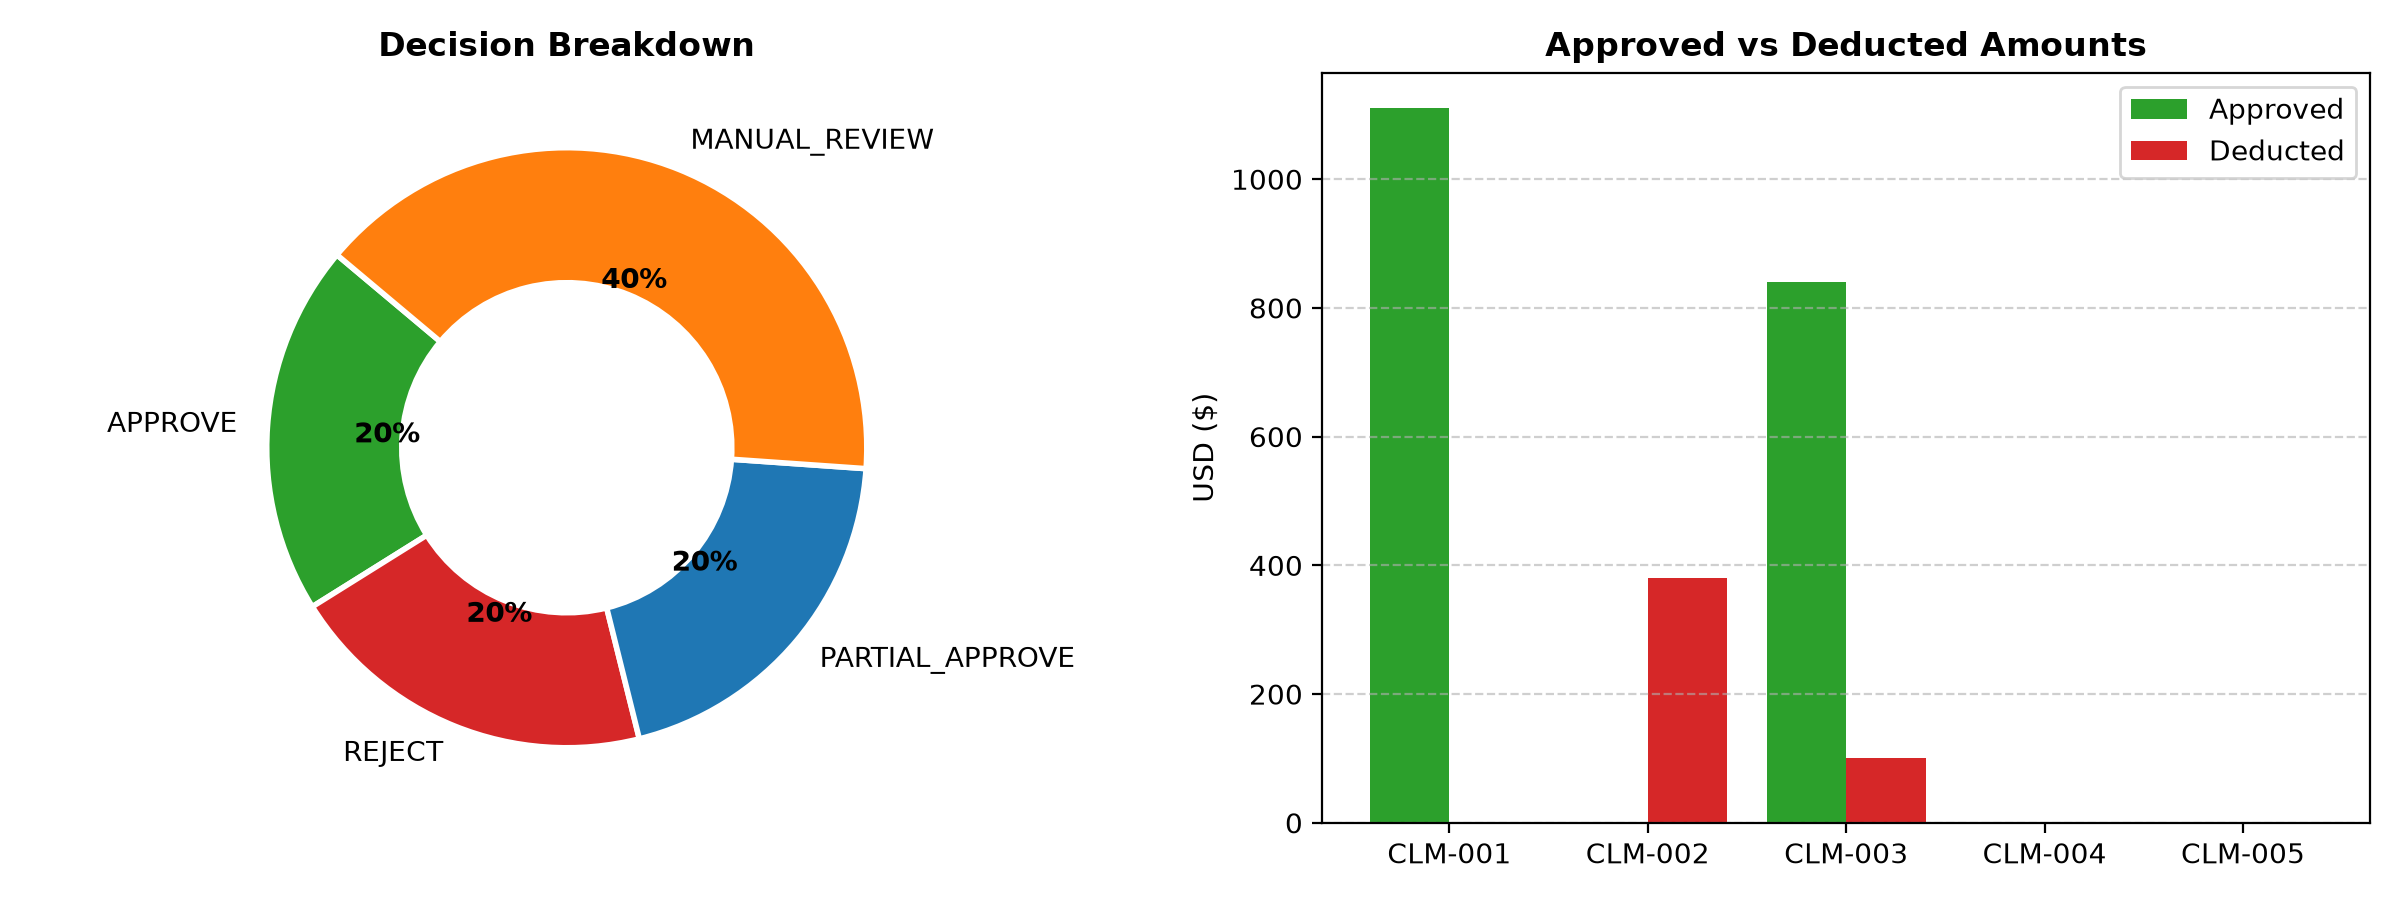

In [134]:
from IPython.display import Image, display
display(Image(filename="UI SS_1.png"))

# Design Notes & Reasoning

### 1. Architectural Philosophy: AI Extracts, Python Decides
- **Determinism & Financial Accuracy**: Reimbursement limits, per-diem math, receipt requirements, and authorization tiers are hard rules. LLMs often hallucinate arithmetic or make subtle rounding errors. Keeping all calculations and policy conditionals in plain Python `if/else` statements ensures 100% mathematical correctness, reproducible outcomes, and zero arithmetic drift.
- **Targeted GenAI Usage**: The LLM is used exclusively where rules fall short: parsing natural language expense descriptions (e.g. recognizing that 'Hotel spa package' is personal entertainment or that 'Round-trip economy airfare' is standard coach travel). It extracts structured flags (`is_ineligible`, `is_premium_cabin`, `nights`, `days`, `ambiguous`) without performing math or making final decisions.
- **Cost & Latency Minimization**: By calling the LLM once per claim with `temperature=0`, small `max_completion_tokens` (4096), and no thinking/reasoning overhead, total latency is minimized and API cost is limited to at most small calls (fractions of a cent total).

### 2. Manual Review Routing Rationale
In enterprise travel reimbursement, automated false approvals create compliance risk, while false rejections damage employee trust. Routing borderline cases to Manual Review protects both parties:
- **Policy Exceptions (POL-AIR-01)**: Business-class airfare is not auto-deducted because legitimate corporate pre-approvals or medical/international exceptions may exist.
- **Receipt Validation (POL-RCT-02)**: Missing receipts trigger manual review rather than auto-rejection, allowing employees to provide documentation.
- **Spending Authority (POL-APR-03)**: Total claims > $2,000 mandate Director approval as an audit control.
- **Conflicting Line Items**: Descriptions where stated rate math conflicts with the claimed amount.
- **Unlisted Categories**: Categories not covered under POL-CAT-01.
- **Missing Durations**: Per-diem expenses missing duration.

### 3. Next Steps & Production Enhancements
- **Multi-modal OCR Pipeline**: Ingest actual PDF/image receipts directly via OCR/vision models to cross-verify invoice line items against claimed amounts.
- **Corporate Card Feed Reconciliation**: Link claim intake to corporate card feeds to cross-check expenses automatically and detect duplicate claims.
- **Interactive Reviewer Portal**: Build a lightweight web UI for finance managers to approve, reject, or request information on claims routed to Manual Review.